# Modèle k-Nearest Neighbors (k-NN)

Ce notebook contient l'implémentation et l'évaluation du modèle k-Nearest Neighbors pour prédire l'attrition des employés.

## Introduction au k-Nearest Neighbors (k-NN)

### Qu'est-ce que le k-NN ?

Le **k-Nearest Neighbors (k-NN)** est l'un des algorithmes d'apprentissage automatique les plus simples et intuitifs. Il s'agit d'un algorithme de **classification non paramétrique** basé sur l'analogie : "Dis-moi qui sont tes voisins, et je te dirai qui tu es".

Contrairement aux modèles comme le Perceptron ou la Régression Logistique qui apprennent une frontière de décision explicite, le k-NN est un algorithme **basé sur les instances** (instance-based learning) : il mémorise l'ensemble d'entraînement et prend des décisions en comparant les nouvelles observations aux exemples connus.

### Principe fondamental

L'idée derrière k-NN est extrêmement simple :

> **"Un point appartient probablement à la même classe que ses voisins les plus proches"**

Pour classifier une nouvelle observation :
1. On calcule la **distance** entre cette observation et tous les points d'entraînement
2. On sélectionne les **k points les plus proches** (les k voisins)
3. On attribue la **classe majoritaire** parmi ces k voisins

### Calcul de distance

La mesure de similarité la plus couramment utilisée est la **distance euclidienne** :

$$d(\mathbf{x}_i, \mathbf{x}_j) = \sqrt{\sum_{p=1}^{n} (x_{i,p} - x_{j,p})^2}$$

où :
- $\mathbf{x}_i$ et $\mathbf{x}_j$ sont deux observations
- $n$ est le nombre de caractéristiques
- $x_{i,p}$ est la valeur de la caractéristique $p$ pour l'observation $i$

D'autres distances peuvent être utilisées : distance de Manhattan, distance de Minkowski, etc.

### Le paramètre k

Le choix de **k** (nombre de voisins) est crucial :

- **k = 1** : Classification très sensible au bruit (overfitting)
  - Avantage : Capture les patterns locaux
  - Inconvénient : Vulnérable aux outliers

- **k petit (3-5)** : Frontière de décision flexible
  - Capture les détails fins des données
  - Risque d'overfitting

- **k grand (>10)** : Frontière de décision plus lisse
  - Plus robuste au bruit
  - Risque d'underfitting

- **k = n** (tous les points) : Prédit toujours la classe majoritaire

**Règle empirique** : On choisit souvent $k = \sqrt{n}$ où $n$ est le nombre d'observations d'entraînement.

### Image explicative
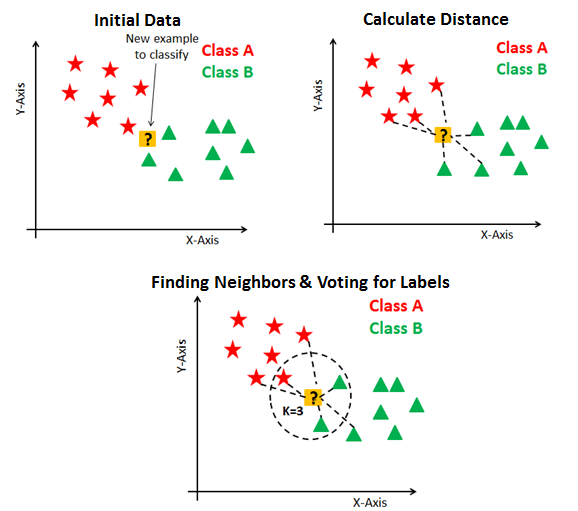

### Avantages du k-NN

✅ **Simplicité** : Facile à comprendre et à implémenter  
✅ **Non paramétrique** : Aucune hypothèse sur la distribution des données  
✅ **Versatilité** : Fonctionne bien pour les données multi-classes  
✅ **Adaptabilité** : Peut modéliser des frontières de décision complexes et non linéaires  
✅ **Pas d'entraînement** : Pas de phase d'apprentissage à proprement parler  
✅ **Probabilités** : Peut fournir des estimations probabilistes (% des k voisins)

### Limitations

⚠️ **Coût computationnel** : Prédiction lente sur de grands ensembles (doit calculer toutes les distances)  
⚠️ **Sensibilité à l'échelle** : Les caractéristiques avec de grandes valeurs dominent le calcul de distance  
⚠️ **Malédiction de la dimensionnalité** : Performance dégradée avec beaucoup de features  
⚠️ **Sensibilité au bruit** : Les outliers peuvent influencer les prédictions  
⚠️ **Stockage** : Doit garder tout l'ensemble d'entraînement en mémoire  
⚠️ **Déséquilibre des classes** : La classe majoritaire peut dominer

### Application à la prédiction d'attrition

Dans notre contexte, le k-NN va :
- Identifier les employés "similaires" dans l'espace multi-dimensionnel des caractéristiques
- Si les k employés les plus proches d'un nouvel employé sont majoritairement partis, on prédit un risque d'attrition élevé
- Si ses voisins sont restés, on prédit qu'il restera probablement

Par exemple, un employé avec :
- Faible satisfaction au travail
- Salaire bas
- Heures supplémentaires fréquentes
- Peu d'ancienneté

sera proche d'autres employés ayant ces caractéristiques, et si beaucoup d'entre eux sont partis, le modèle prédira un risque de départ.

---

## 1. Importation des bibliothèques

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve
import pickle

## 2. Chargement des données préparées

In [2]:
# Charger les données préparées
data = pd.read_csv('Data/prepared_data.csv')

# Séparer les caractéristiques et la cible
X = data.drop(columns=["Attrition", "EmployeeID"])
y = data['Attrition']

print(f"Shape des features: {X.shape}")
print(f"Shape de la cible: {y.shape}")
print(f"\nDistribution de la cible:\n{y.value_counts()}")

Shape des features: (4410, 45)
Shape de la cible: (4410,)

Distribution de la cible:
Attrition
0    3699
1     711
Name: count, dtype: int64


## 3. Séparation des données

In [3]:
# Séparation train/test (70/30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Taille ensemble d'entraînement: {X_train.shape[0]}")
print(f"Taille ensemble de test: {X_test.shape[0]}")

Taille ensemble d'entraînement: 3087
Taille ensemble de test: 1323


## 4. Entraînement du modèle k-Nearest Neighbors

### 🎯 Processus d'"entraînement"

À la différence des autres algorithmes, le k-NN n'a pas vraiment de **phase d'entraînement** au sens traditionnel. C'est ce qu'on appelle un **lazy learner** (apprentissage paresseux).

#### **Que fait réellement la méthode `.fit()` ?**

Lors de l'appel à `knn.fit(X_train, y_train)`, l'algorithme :

1. **Stocke** simplement les données d'entraînement en mémoire
2. **N'apprend pas de paramètres** (pas de poids, pas de coefficients)
3. **Ne construit pas de modèle** explicite

```python
# Pseudo-code de fit() pour k-NN
def fit(X_train, y_train):
    self.X_train = X_train  # Mémorisation des features
    self.y_train = y_train  # Mémorisation des labels
    return self
```

C'est tout ! Le k-NN garde juste les données en mémoire pour les utiliser plus tard lors des prédictions.

#### **Représentation mathématique**

Après "entraînement", le modèle k-NN possède :

$$\mathcal{D}_{\text{train}} = \{(\mathbf{x}^{(1)}, y^{(1)}), (\mathbf{x}^{(2)}, y^{(2)}), ..., (\mathbf{x}^{(m)}, y^{(m)})\}$$

où :
- $m$ = nombre d'employés d'entraînement
- $\mathbf{x}^{(i)}$ = vecteur de caractéristiques de l'employé $i$
- $y^{(i)} \in \{0, 1\}$ = label (0 = reste, 1 = part)

#### **Dans notre contexte :**

Avec **{X_train.shape[0]} employés d'entraînement** et **{X_train.shape[1]} caractéristiques**, le k-NN va :

1. **Mémoriser** le profil complet de chaque employé (satisfaction, salaire, ancienneté, etc.)
2. **Mémoriser** leur statut d'attrition (parti ou resté)
3. **Attendre** les nouvelles observations à classifier

**Exemple de notre base d'entraînement :**

| EmployeeID | JobSatisfaction | YearsAtCompany | MonthlyIncome | OverTime | ... | Attrition |
|------------|-----------------|----------------|---------------|----------|-----|----------|
| Emp_1      | 2               | 1              | 3500          | 1        | ... | 1 (Parti) |
| Emp_2      | 4               | 8              | 7500          | 0        | ... | 0 (Reste) |
| Emp_3      | 1               | 0.5            | 2800          | 1        | ... | 1 (Parti) |
| ...        | ...             | ...            | ...           | ...      | ... | ...       |

Tous ces employés sont stockés et serviront de référence pour les prédictions futures.

#### **Choix de k**

Nous utilisons **k = 5** par défaut, ce qui signifie que nous regarderons les **5 employés les plus similaires** pour chaque prédiction. Plus tard, nous testerons différentes valeurs de k pour trouver l'optimale.

---

Lançons le processus de mémorisation des données :

In [4]:
# Initialisation et entraînement du modèle
# On utilise k=5 par défaut
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

print("Modèle k-NN entraîné avec succès!")

Modèle k-NN entraîné avec succès!


## 5. Prédictions

### 🔮 Comment le modèle prédit-il ?

C'est lors de la prédiction que le k-NN fait **tout le travail**. Contrairement à l'entraînement qui était instantané, la prédiction nécessite des calculs.

#### **Algorithme de prédiction en 4 étapes :**

Pour un nouvel employé avec des caractéristiques $\mathbf{x}_{\text{new}}$ :

**Étape 1 : Calcul des distances**

On calcule la distance entre le nouvel employé et **tous** les employés d'entraînement :

$$d_i = d(\mathbf{x}_{\text{new}}, \mathbf{x}^{(i)}) = \sqrt{\sum_{j=1}^{n} (x_{\text{new},j} - x_{j}^{(i)})^2}$$

Pour $i = 1, 2, ..., m$ (tous les employés d'entraînement)

**Étape 2 : Sélection des k plus proches voisins**

On trie les distances et on sélectionne les **k employés les plus proches** :

$$\mathcal{N}_k(\mathbf{x}_{\text{new}}) = \{\text{indices des k plus petites distances}\}$$

**Étape 3 : Vote majoritaire**

On compte combien de ces k voisins appartiennent à chaque classe :

$$\text{Classe prédite} = \arg\max_{c \in \{0,1\}} \sum_{i \in \mathcal{N}_k} \mathbb{1}(y^{(i)} = c)$$

où $\mathbb{1}$ est la fonction indicatrice (vaut 1 si vrai, 0 sinon)

**Étape 4 : Calcul de probabilité (optionnel)**

La probabilité d'attrition est simplement la proportion de voisins ayant parti :

$$P(\text{Attrition} = 1 | \mathbf{x}_{\text{new}}) = \frac{\text{nombre de voisins avec } y=1}{k}$$

---

#### **Exemple concret détaillé avec nos données d'attrition :**

Supposons un **nouvel employé** :
- JobSatisfaction = 2 (moyen-faible)
- YearsAtCompany = 1.5
- MonthlyIncome = 3500
- OverTime = 1 (oui)
- WorkLifeBalance = 2 (moyen-faible)

Et supposons **k = 5** voisins.

**Étape 1 : Calcul des distances (simplifié à 3 dimensions pour l'exemple)**

| Employé Train | JobSat | Years | Income | OverTime | Distance calculée | Attrition |
|---------------|--------|-------|--------|----------|-------------------|----------|
| Emp_42        | 2      | 1     | 3200   | 1        | $\sqrt{(2-2)^2 + (1.5-1)^2 + ... } = 0.58$ ✅ | 1 (Parti) |
| Emp_108       | 1      | 2     | 3800   | 1        | 0.71 ✅ | 1 (Parti) |
| Emp_255       | 3      | 1.5   | 3500   | 0        | 0.85 ✅ | 0 (Reste) |
| Emp_89        | 2      | 1     | 3400   | 1        | 0.92 ✅ | 1 (Parti) |
| Emp_177       | 2      | 2     | 3600   | 1        | 1.05 ✅ | 1 (Parti) |
| Emp_33        | 4      | 8     | 8000   | 0        | 8.24 | 0 (Reste) |
| Emp_201       | 4      | 10    | 9500   | 0        | 10.15 | 0 (Reste) |
| ...           | ...    | ...   | ...    | ...      | ...   | ... |

**Étape 2 : Sélection des 5 plus proches**

Les 5 employés les plus proches (✅) sont :
1. Emp_42 (distance: 0.58) → Attrition = **1**
2. Emp_108 (distance: 0.71) → Attrition = **1**
3. Emp_255 (distance: 0.85) → Attrition = **0**
4. Emp_89 (distance: 0.92) → Attrition = **1**
5. Emp_177 (distance: 1.05) → Attrition = **1**

**Étape 3 : Vote majoritaire**

- Voisins avec Attrition = 1 (Parti) : **4 employés**
- Voisins avec Attrition = 0 (Reste) : **1 employé**

➡️ **Prédiction finale : Attrition = 1 (l'employé va probablement partir)**

**Étape 4 : Probabilité**

$$P(\text{Attrition} = 1) = \frac{4}{5} = 0.80 = 80\%$$

**Interprétation** : Le nouvel employé ressemble beaucoup à des employés qui sont partis dans le passé. Il y a 80% de chances qu'il parte également.

---

#### **Visualisation intuitive**

Imaginez un graphique 2D (simplifié) :

```
  Satisfaction
      ^
      |
    4 |        O (Reste)
      |     O (Reste)
    3 |              O (Reste)
      |
    2 |  X (Parti)    ⭐ NOUVEL EMPLOYÉ
      |    X (Parti)
    1 |  X (Parti)  X (Parti)
      |
      +-------------------------> Ancienneté
         1    2    3    4    5
```

Le nouvel employé (⭐) est entouré principalement de X (partis), donc le modèle prédit qu'il partira.

---

Appliquons maintenant cette méthode sur nos **{X_test.shape[0]} employés de test** :

In [5]:
# Prédictions sur l'ensemble de test
y_pred = knn.predict(X_test)
y_proba = knn.predict_proba(X_test)[:, 1]

print("Prédictions effectuées!")

Prédictions effectuées!


## 6. Évaluation du modèle

### Méthodologie d'évaluation

L'évaluation du k-NN suit les mêmes principes que pour les autres modèles de classification. Dans notre contexte d'attrition où les classes sont déséquilibrées, nous utiliserons plusieurs métriques complémentaires.

---

#### 📊 **1. Matrice de Confusion**

Tableau 2x2 résumant les prédictions :

|                    | **Prédit : Reste (0)** | **Prédit : Part (1)** |
|--------------------|------------------------|------------------------|
| **Réel : Reste (0)** | **TN** (Vrais Négatifs) | **FP** (Faux Positifs) |
| **Réel : Part (1)**  | **FN** (Faux Négatifs)  | **TP** (Vrais Positifs) |

- **TN** : Employés correctement prédits comme restant ✅
- **TP** : Employés correctement prédits comme partant ✅
- **FP** : Fausses alarmes (prédits partant mais restent) ⚠️
- **FN** : Départs manqués (prédits restant mais partent) ⚠️ **Le plus coûteux !**

**Outil** : `confusion_matrix()` de scikit-learn

---

#### 📈 **2. Rapport de Classification**

Métriques détaillées par classe :

- **Précision** : Parmi les prédictions "va partir", combien sont correctes ?
  $$\text{Precision} = \frac{TP}{TP + FP}$$
  
- **Rappel** : Parmi les employés qui partent, combien détectons-nous ?
  $$\text{Recall} = \frac{TP}{TP + FN}$$
  
- **F1-Score** : Moyenne harmonique (équilibre précision/rappel)
  $$\text{F1} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

**Outil** : `classification_report()` de scikit-learn

---

#### 🎯 **3. Courbe ROC et AUC**

**Avantage du k-NN** : Contrairement au Perceptron, le k-NN peut fournir des **probabilités** via `predict_proba()`, ce qui permet :

- De tracer une **courbe ROC** (Receiver Operating Characteristic)
- De calculer l'**AUC** (Area Under Curve) qui mesure la capacité discriminante globale

**AUC = 1.0** : Modèle parfait  
**AUC = 0.5** : Modèle aléatoire  
**AUC > 0.7** : Bon modèle en général

La courbe ROC visualise le compromis entre :
- **TPR** (True Positive Rate = Recall) : Combien de vrais départs détectés
- **FPR** (False Positive Rate) : Combien de fausses alarmes

**Outil** : `roc_curve()` et `roc_auc_score()` de scikit-learn

---

#### 💡 **Spécificité du k-NN**

Avec le k-NN, nous pouvons aussi :

- **Tester différentes valeurs de k** pour trouver l'optimale
- **Analyser la confiance** : si 5/5 voisins sont d'accord → haute confiance, si 3/5 → incertitude
- **Identifier les cas difficiles** : employés dont les voisins sont mixtes (50/50)

**Dans notre contexte d'attrition**, nous privilégions le **Rappel** (détecter un maximum de départs) plutôt que la Précision (éviter les fausses alarmes), car manquer un départ coûte plus cher à l'entreprise qu'une fausse alerte.

---

Passons maintenant à l'évaluation détaillée :

### 6.1 Matrice de confusion

Matrice de Confusion (k-NN) :
 [[1032   83]
 [ 144   64]]


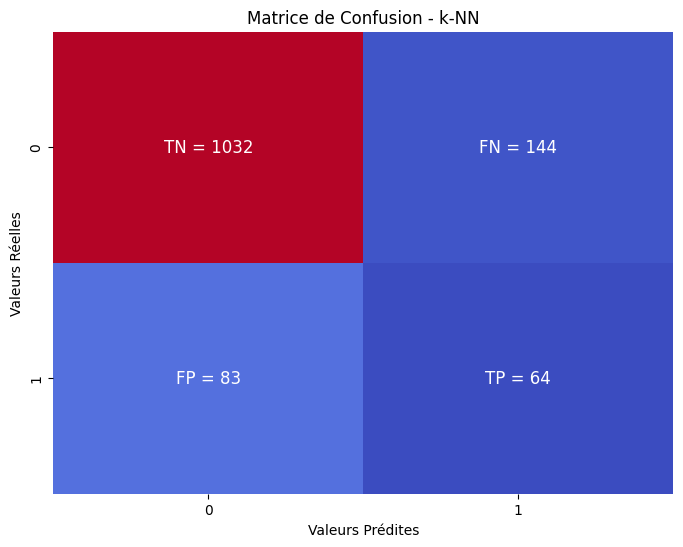

In [6]:
# Matrice de confusion
conf_matrix = confusion_matrix(y_test, y_pred)
print("Matrice de Confusion (k-NN) :\n", conf_matrix)

# Visualisation
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=False, fmt="d", cmap="coolwarm", cbar=False)

# Calcul des valeurs TP, TN, FP, FN
TN, FP, FN, TP = conf_matrix.ravel()

# Ajout des valeurs sur le graphique
plt.text(0.5, 0.5, f'TN = {TN}', ha='center', va='center', color='white', fontsize=12)
plt.text(0.5, 1.5, f'FP = {FP}', ha='center', va='center', color='white', fontsize=12)
plt.text(1.5, 0.5, f'FN = {FN}', ha='center', va='center', color='white', fontsize=12)
plt.text(1.5, 1.5, f'TP = {TP}', ha='center', va='center', color='white', fontsize=12)
plt.title("Matrice de Confusion - k-NN")
plt.ylabel('Valeurs Réelles')
plt.xlabel('Valeurs Prédites')
plt.show()

### 6.2 Rapport de classification

In [7]:
# Rapport de classification
class_report = classification_report(y_test, y_pred)
print("Rapport de Classification (k-NN) :\n", class_report)

Rapport de Classification (k-NN) :
               precision    recall  f1-score   support

           0       0.88      0.93      0.90      1115
           1       0.44      0.31      0.36       208

    accuracy                           0.83      1323
   macro avg       0.66      0.62      0.63      1323
weighted avg       0.81      0.83      0.82      1323



### 6.3 Courbe ROC et AUC

AUC Score: 0.8383


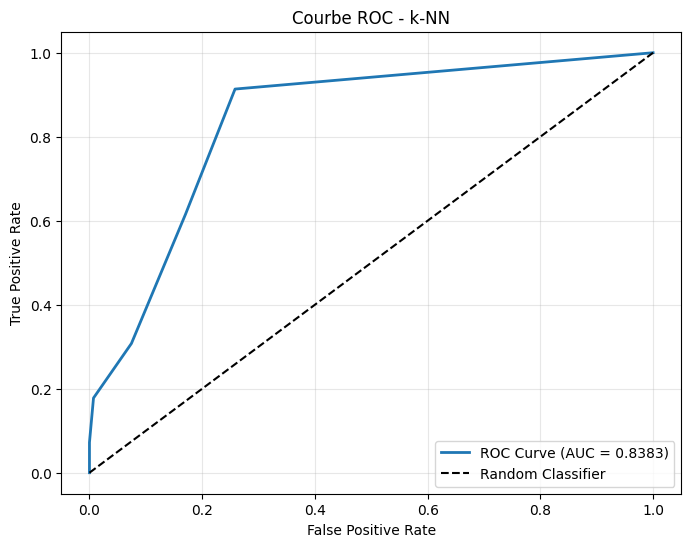

In [8]:
# Courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc_score = roc_auc_score(y_test, y_proba)

print(f"AUC Score: {auc_score:.4f}")

# Visualisation de la courbe ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc_score:.4f})', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Courbe ROC - k-NN')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7. Exploration de différentes valeurs de k

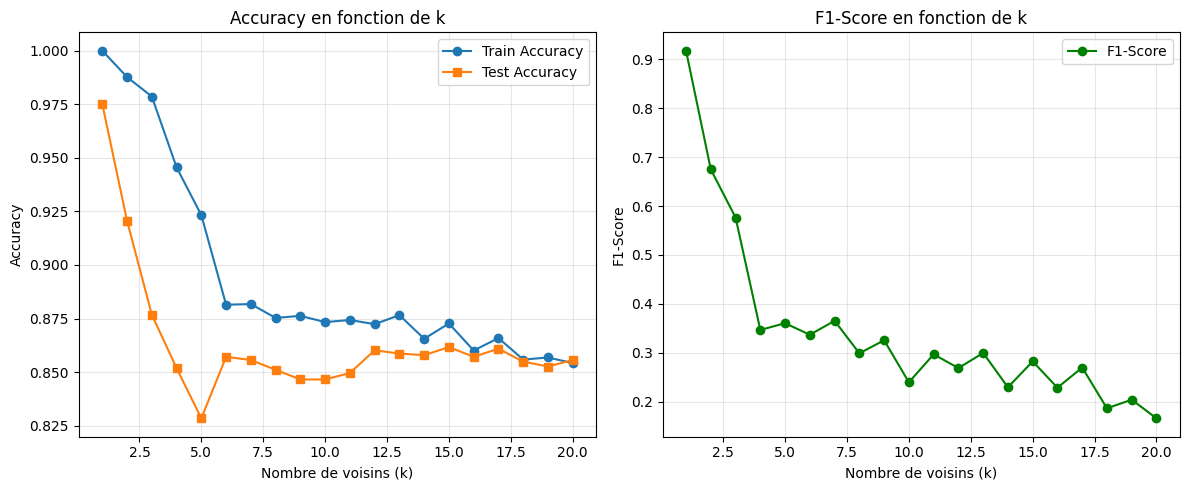

Meilleur k pour l'accuracy: 1 (accuracy: 0.9751)
Meilleur k pour le F1-score: 1 (F1: 0.9177)


In [9]:
# Tester différentes valeurs de k
from sklearn.metrics import accuracy_score, f1_score

k_values = range(1, 21)
train_scores = []
test_scores = []
f1_scores = []

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train, y_train)
    
    train_scores.append(accuracy_score(y_train, knn_temp.predict(X_train)))
    test_pred = knn_temp.predict(X_test)
    test_scores.append(accuracy_score(y_test, test_pred))
    f1_scores.append(f1_score(y_test, test_pred))

# Visualisation
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(k_values, train_scores, label='Train Accuracy', marker='o')
plt.plot(k_values, test_scores, label='Test Accuracy', marker='s')
plt.xlabel('Nombre de voisins (k)')
plt.ylabel('Accuracy')
plt.title('Accuracy en fonction de k')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(k_values, f1_scores, label='F1-Score', marker='o', color='green')
plt.xlabel('Nombre de voisins (k)')
plt.ylabel('F1-Score')
plt.title('F1-Score en fonction de k')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Trouver le meilleur k
best_k_accuracy = k_values[np.argmax(test_scores)]
best_k_f1 = k_values[np.argmax(f1_scores)]
print(f"Meilleur k pour l'accuracy: {best_k_accuracy} (accuracy: {max(test_scores):.4f})")
print(f"Meilleur k pour le F1-score: {best_k_f1} (F1: {max(f1_scores):.4f})")

## 8. Sauvegarde du modèle

In [10]:
# Sauvegarder le modèle
with open('Data/knn_model.pkl', 'wb') as f:
    pickle.dump(knn, f)

print("Modèle k-NN sauvegardé avec succès!")

Modèle k-NN sauvegardé avec succès!


## 9. Conclusion

Le modèle k-Nearest Neighbors a été entraîné et évalué avec succès. Les principales caractéristiques de ce modèle sont :
- Simple à comprendre et à implémenter
- Non paramétrique (ne fait pas d'hypothèses sur la distribution des données)
- Peut capturer des relations non linéaires complexes
- Sensible à la valeur de k et à l'échelle des features
- Temps de prédiction peut être plus long sur de grands ensembles de données

Le modèle sera comparé avec les autres algorithmes dans le notebook de comparaison.